In [ ]:
'''
gonna make the confusion matrix and yellow graph
for the averages of 5 cnns
'''

In [3]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import precision_recall as pr
import gc  # garbage collector
import review_findings_functions as rff
import os
import importlib
import implantation_functions as imp

In [4]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [5]:
save_name='offset_sat_newhparam_b50_allstamps_satdumbsplit_folds'

In [22]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [18]:
folds=0

In [21]:
type(1)

int

In [19]:
np.load("/home/3155/saved_loss/label_pred_te_"+save_name+"_fold_"+str(folds)+".npy")

array([[1.4810407e-02, 1.4024752e-01, 2.3036516e-01, 1.7035737e-17,
        6.1457694e-01, 2.2945518e-14],
       [1.4246620e-02, 1.0691880e-01, 3.3687812e-01, 1.1116558e-18,
        5.4195637e-01, 1.5303919e-15],
       [4.1656829e-03, 9.5707703e-01, 5.6750407e-03, 2.1438814e-20,
        3.3082224e-02, 8.9545232e-16],
       ...,
       [8.1917839e-03, 3.2327583e-01, 1.1206692e-01, 3.1631635e-18,
        5.5646545e-01, 5.5084277e-14],
       [1.0000000e+00, 9.5635696e-12, 2.8511682e-09, 1.4875267e-36,
        4.5665371e-11, 1.5374089e-25],
       [1.8289618e-02, 2.2904575e-01, 1.4453521e-01, 2.0409537e-16,
        6.0812950e-01, 1.7502269e-13]], dtype=float32)

In [20]:
folds=1
np.load("/home/3155/saved_loss/label_pred_te_"+save_name+"_fold_"+str(folds)+".npy")

array([[1.2835143e-02, 1.3536283e-01, 2.1691875e-01, 1.0944548e-16,
        6.3488322e-01, 9.1203790e-15],
       [9.2129856e-03, 8.8408977e-02, 3.9176050e-01, 3.4196186e-18,
        5.1061761e-01, 1.7621727e-15],
       [3.1333580e-03, 9.4447172e-01, 5.4342174e-03, 2.4725088e-18,
        4.6960663e-02, 8.7527523e-15],
       ...,
       [8.1523946e-03, 3.9344618e-01, 9.4312690e-02, 5.8931225e-17,
        5.0408876e-01, 3.8108114e-14],
       [1.0000000e+00, 1.2507160e-16, 3.0112147e-17, 0.0000000e+00,
        3.0769209e-20, 0.0000000e+00],
       [1.4517471e-02, 2.2534628e-01, 1.4807197e-01, 1.6103964e-18,
        6.1206430e-01, 1.1326205e-15]], dtype=float32)

In [39]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [ ]:
rff.show_confusion_matrix(save_name, sats=True, label_pred_te=None, targ_te=None, folds='average', title="Normalized Confusion Matrix - Subset", absolute=False, subset=.1)

loading data


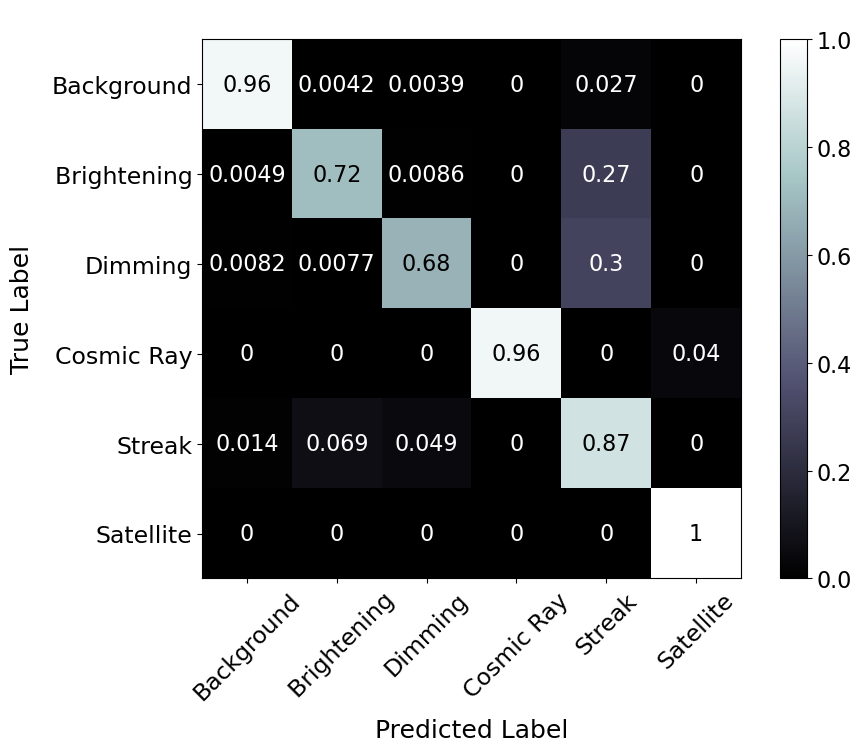

In [47]:
rff.show_confusion_matrix(save_name, sats=True, label_pred_te=None, targ_te=None, folds='average', title=" ", absolute=False)

loading data


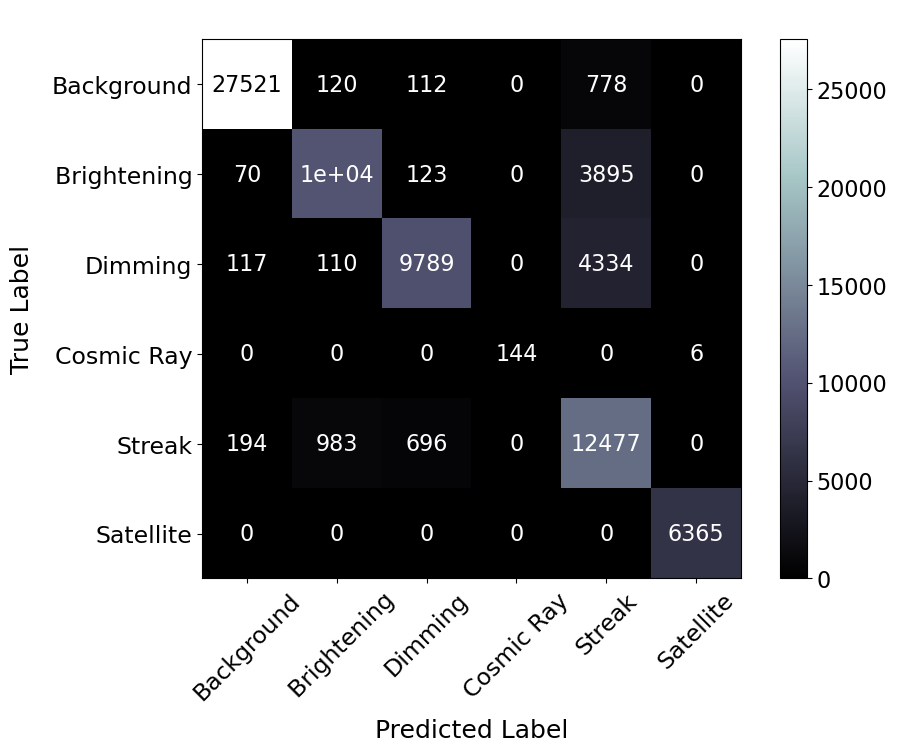

In [48]:
rff.show_confusion_matrix(save_name, sats=True, label_pred_te=None, targ_te=None, folds='average', title=" ", absolute=True)

In [37]:
info_te = np.load('/home/3155/saved_loss/offset_sat_newhparam_b50_allstamps_satdumbsplit_folds_info_te.npy')

In [36]:
targ_te = np.load('/home/3155/saved_loss/targ_te_offset_sat_newhparam_b50_allstamps_satdumbsplit_folds.npy')

In [38]:
our_bness_te = np.load('/home/3155/saved_loss/our_bness_te_offset_sat_newhparam_b50_allstamps_satdumbsplit.npy')

In [54]:
our_bness_te

array([0.95, 1.4 , 1.05, ..., 0.95, 0.95, 1.4 ])

In [51]:
targ_te

array([4, 2, 1, ..., 4, 0, 4])

In [20]:
mask = np.sum(([targ_te==2],[targ_te==1]), axis=0)[0]

In [21]:
mask

array([0, 1, 1, ..., 0, 0, 0])

In [69]:
info_te[mask[0].astype(bool)]

array([[ 382,    0,    4,  661,  799,    0],
       [ 476,    1,    9, 1574, 2757,    2],
       [ 301,    1,    9, 2784, 1538,   -1],
       ...,
       [ 612,    0,    3, 1233, 2128,    1],
       [  53,    0,    4, 1290, 2026,    2],
       [ 474,    1,    4,  387,  429,    0]])

In [62]:
info_te

array([[ 647,    0,    0, 2427,  331,    1],
       [ 382,    0,    4,  661,  799,    0],
       [ 476,    1,    9, 1574, 2757,    2],
       ...,
       [1099,    0,    0,  840, 1340,    0],
       [2460,    0,    0,  307,  230,  -12],
       [ 349,    0,    0, 1374, 1325,    2]])

In [86]:
info_te_copy = info_te.copy().astype(float)

In [76]:
mask[0][1]

1

In [87]:
second_index = 0
for i in range(len(info_te)):
    if mask[0][i]==1:
        info_te_copy[i][1] = our_bness_te[second_index]
        second_index+=1

In [88]:
info_te_copy

array([[ 6.470e+02,  0.000e+00,  0.000e+00,  2.427e+03,  3.310e+02,
         1.000e+00],
       [ 3.820e+02,  9.500e-01,  4.000e+00,  6.610e+02,  7.990e+02,
         0.000e+00],
       [ 4.760e+02,  1.400e+00,  9.000e+00,  1.574e+03,  2.757e+03,
         2.000e+00],
       ...,
       [ 1.099e+03,  0.000e+00,  0.000e+00,  8.400e+02,  1.340e+03,
         0.000e+00],
       [ 2.460e+03,  0.000e+00,  0.000e+00,  3.070e+02,  2.300e+02,
        -1.200e+01],
       [ 3.490e+02,  0.000e+00,  0.000e+00,  1.374e+03,  1.325e+03,
         2.000e+00]])

In [89]:
targ_te_copy = targ_te.copy

In [91]:
targ_te[0].type

AttributeError: 'numpy.int64' object has no attribute 'type'

In [5]:
subset=.1
#okay so maybe what we really want is a mask that we can apply to 
#targ and pred so that we just drop the dim ones
newmask = np.zeros(len(targ_te))
secondindex = 0
for i, targ in enumerate(targ_te):
    if targ in [1,2]:
        if our_bness_te[secondindex] >= (1 + subset):
            newmask[i]=1
        elif our_bness_te[secondindex]  <= (1 - subset):
            newmask[i]=1
        secondindex+=1
    else:
        newmask[i]=1

NameError: name 'targ_te' is not defined

In [4]:
def make_mask(targ_te, our_bness_te, subset):
    newmask = np.zeros(len(targ_te))
    secondindex = 0
    for i, targ in enumerate(targ_te):
        if targ in [1,2]:
            if our_bness_te[secondindex] >= (1 + subset):
                newmask[i]=1
            elif our_bness_te[secondindex]  <= (1 - subset):
                newmask[i]=1
            secondindex+=1
        else:
            newmask[i]=1
    return newmask.astype(bool)

In [39]:
newmask = make_mask(targ_te, our_bness_te, subset=.1)

In [95]:
secondindex

28700

In [96]:
len(our_bness_te)

28700

In [9]:
np.sum(newmask)

68556.0

In [99]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [101]:
np.load("/home/3155/saved_loss/label_pred_te_"+save_name+".npy")

FileNotFoundError: [Errno 2] No such file or directory: '/home/3155/saved_loss/label_pred_te_offset_sat_newhparam_b50_allstamps_satdumbsplit_folds.npy'

In [102]:
newmask

array([1., 0., 1., ..., 1., 1., 1.])

In [11]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

loading data


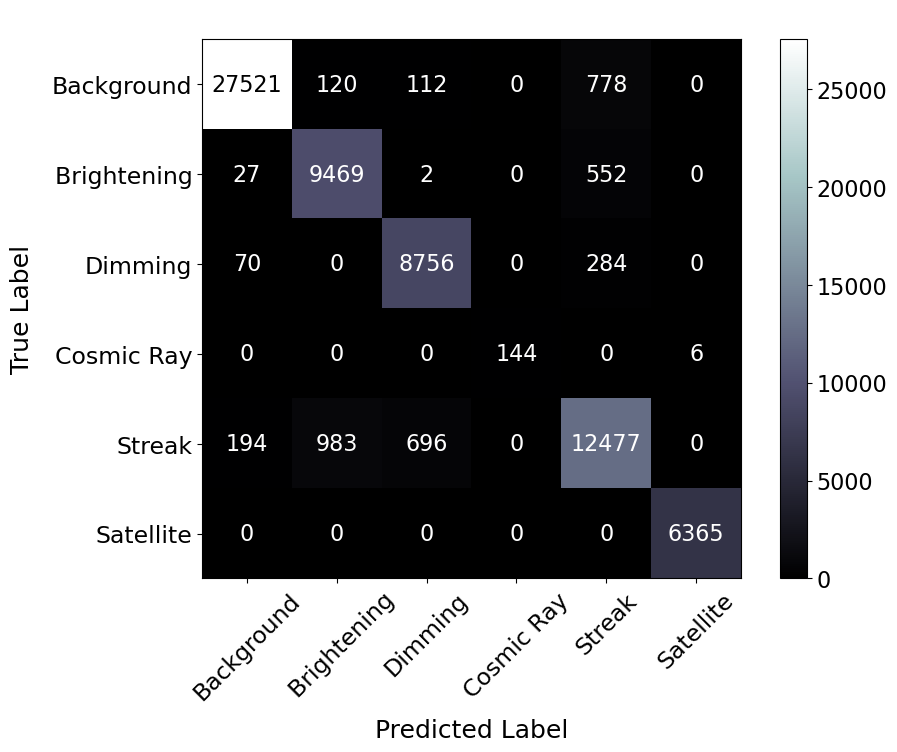

In [49]:
# Absolute CM for Significant (≥ 10%) Transients
rff.show_confusion_matrix(save_name, sats=True, label_pred_te=None, targ_te=None, folds='average', title=" ", absolute=True,mask=newmask )

loading data


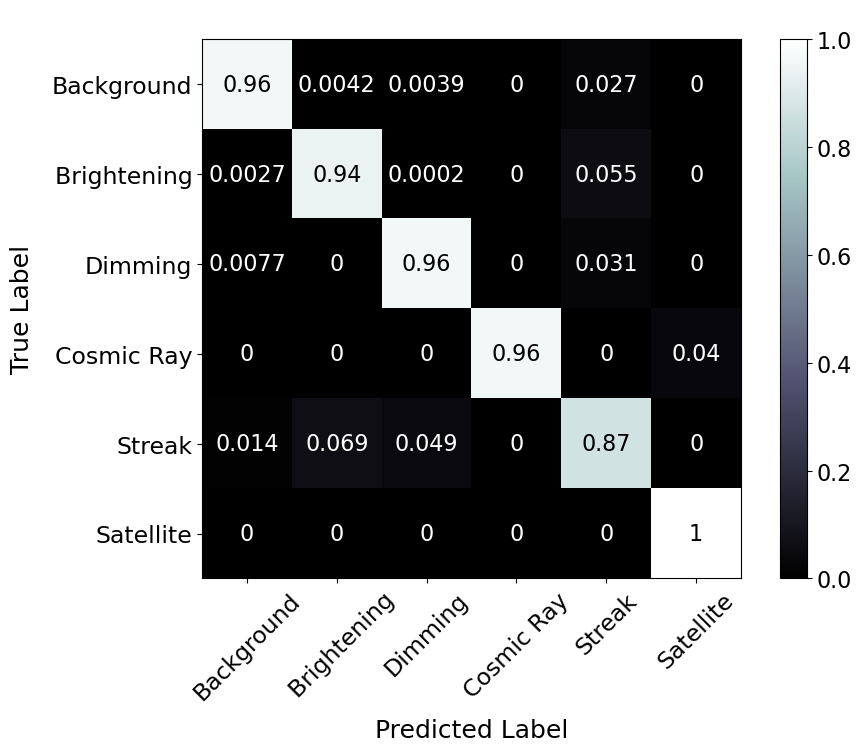

In [50]:
# Normalized CM for Significant (≥ 10%) Transients
rff.show_confusion_matrix(save_name, sats=True, label_pred_te=None, targ_te=None, folds='average', title=" ", absolute=False,mask=newmask )

In [72]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/rwe/review_findings_functions.py'>

In [ ]:
rff.heatmap(save_name, folds=True, color1='#EADFF5', color2='#37153B',tlight='#EEEEEE', tdark='#510163')

In [ ]:
rff.heatmap(save_name, folds=True, color1='#BCE3DD', color2='#164E5C',tlight='#FFFFFF', tdark='#510163')

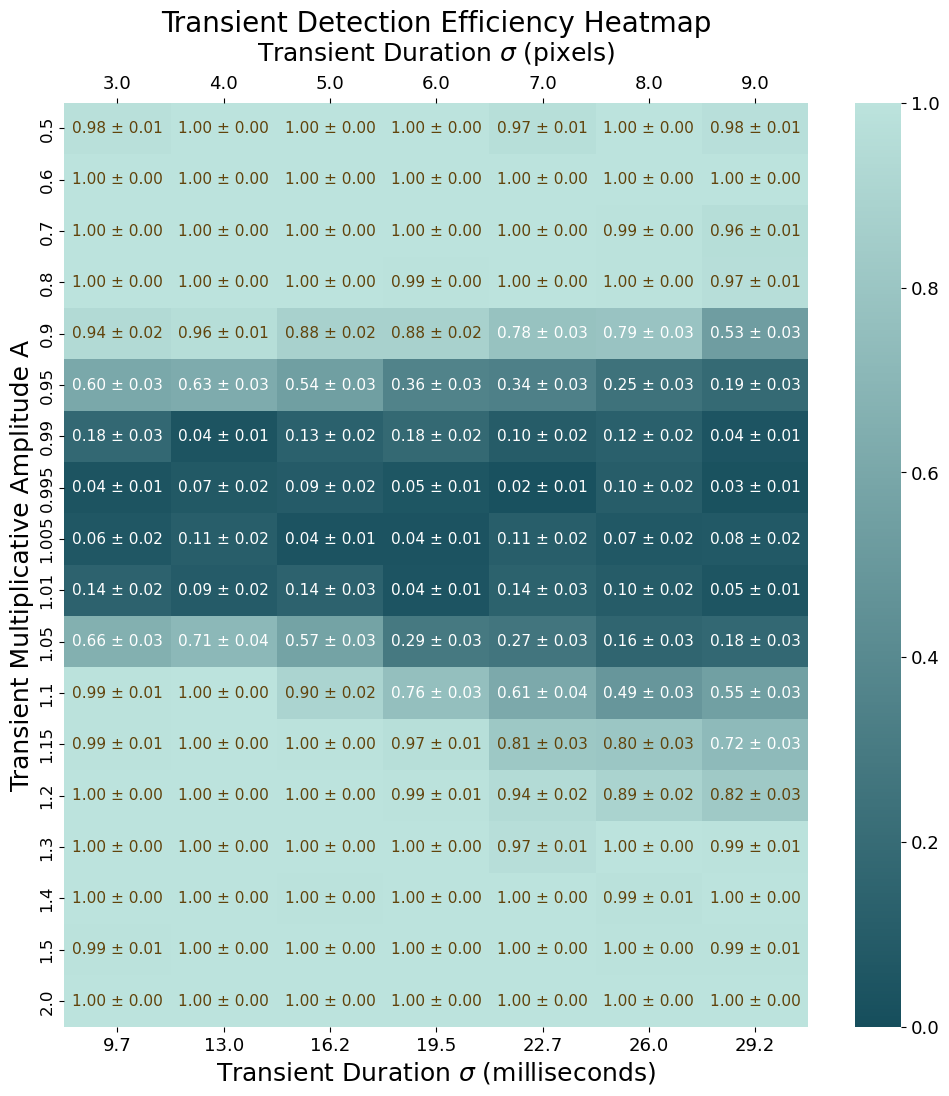

In [14]:
rff.heatmap(save_name, folds=True, color1='#BCE3DD', color2='#164E5C',tlight='#FFFFFF', tdark='#61430B')

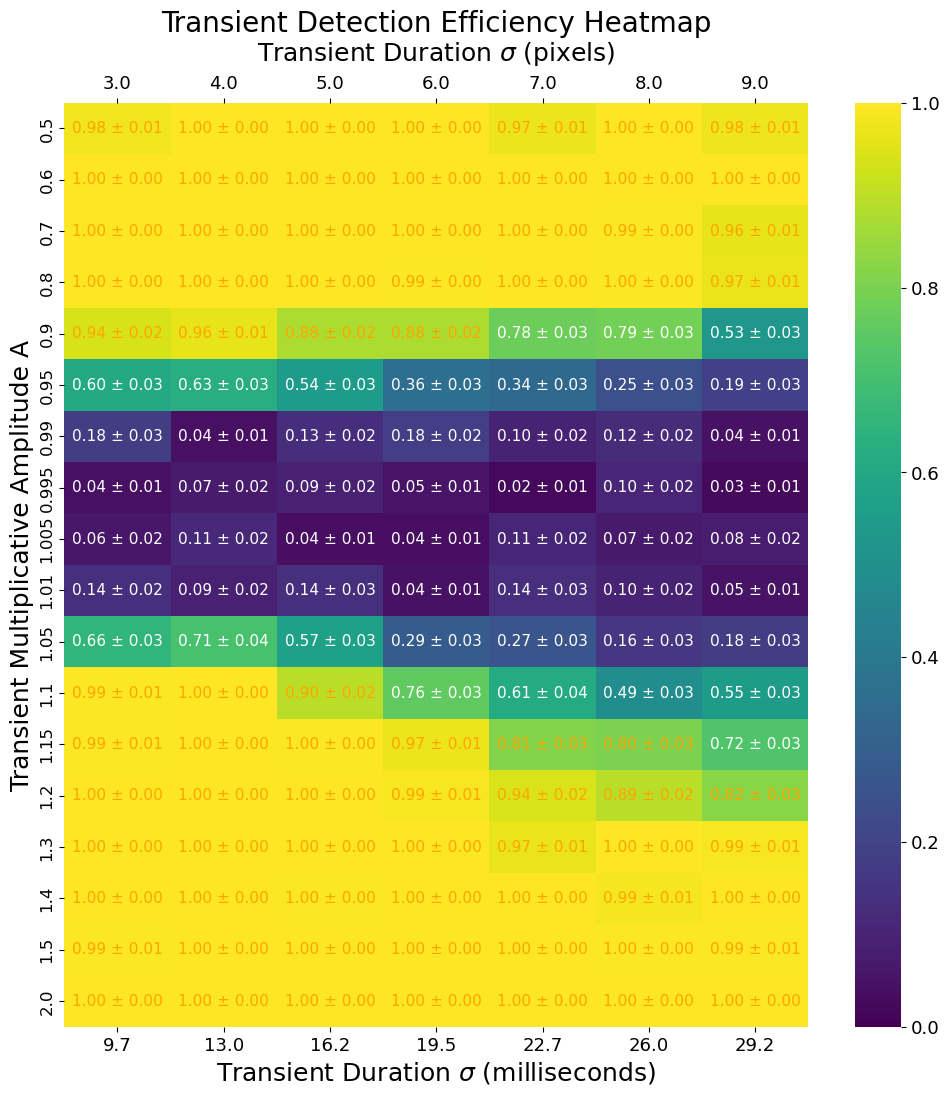

In [33]:
rff.heatmap(save_name, folds=True)

In [17]:
mask

array([0, 1, 1, ..., 0, 0, 0])

In [19]:
label_pred_te.shape

(78096, 6)

In [20]:
mask.shape

(78096,)

In [21]:
label_pred_te[mask].shape

(78096, 6)

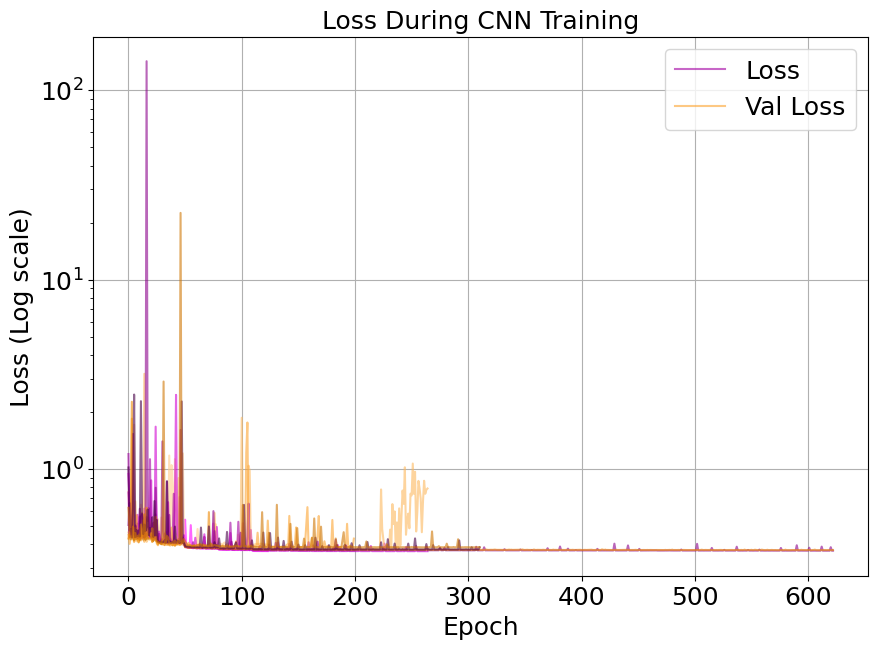

In [28]:
#'newhparam_midstreak',
#"newrange_50_mindelta_p50"
#,  "newrange_25", "newrange_10",
keys = ["offset_sat_newhparam_b50_allstamps_satdumbsplit_folds"]#,"offset_nosat_newhparam_b50_allstamps"]#"newrange_25_mindelta_p50","newrange_50", "newrange_50_mindelta", ,"newrange_50_mindelta"]#, "newrange_500",  "offset_sat_small", "less_offset" #"sat_nnbigger",'offset', 
# keys = ["sat_finalhparam_div4","offset_sat_morestamps",  'sat_nnbigger', "sat_nnbigger_nopool",]
# keys = ['newhparam_midstreak',"sat_finalhparam_div4"]#,"offset_sat_morestamps"]
numbers = ["0","1","2","3","4"]
colors = ["orange",  "purple", "green","orange","red"]*2
colors2 = ["purple", "lightskyblue", "mediumpurple",  "limegreen", "bisque"]*2
valcolors = ["#FECC8B","#FDB85D","#FDA430","#ED8802","#CF7602"]
regcolors = ["#FF00FF","#D100D1","#A300A3","#8B008B","#470047"]
alpha=.6
# for i, key in enumerate(keys):

for j, number in enumerate(numbers):
    loss = np.load("/home/3155/saved_loss/"+key+"_loss_history"+number+".npy")
    val_loss = np.load("/home/3155/saved_loss/"+key+"_val_loss_history"+number+".npy")
    # accuracy = np.load("/home/3155/saved_loss/"+key+"_accuracy_history"+number+".npy")
    # val_accuracy = np.load("/home/3155/saved_loss/"+key+"_val_accuracy_history"+number+".npy")
    # print(number)
    if number=="2":
        plt.plot(loss, label='Loss', alpha=alpha, c=regcolors[j])
        plt.plot(val_loss, label='Val Loss', alpha=alpha, c=valcolors[j])
    else:
        plt.plot(loss, alpha=alpha, c=regcolors[j])
        plt.plot(val_loss,  alpha=alpha, c=valcolors[j])            
# for j, key in enumerate(['newrange']):
#     loss = np.load("/home/3155/saved_loss/"+key+"_loss_history.npy")
#     val_loss = np.load("/home/3155/saved_loss/"+key+"_val_loss_history.npy")
#     accuracy = np.load("/home/3155/saved_loss/"+key+"_accuracy_history.npy")
#     val_accuracy = np.load("/home/3155/saved_loss/"+key+"_val_accuracy_history.npy")
#     plt.plot(loss, label='loss '+key, alpha=.7, c=colors[i + j+1])
#     plt.plot(val_loss, label='val loss '+key, alpha=.7, c=colors2[i + j + 1])
plt.yscale("log")
plt.legend(fontsize=18)
plt.xlabel("Epoch", fontsize=18)
plt.ylabel("Loss (Log scale)", fontsize=18)
plt.title("Loss During CNN Training", fontsize=18)
plt.tick_params(axis="both", labelsize=18)
# plt.xlim(0,45)
plt.grid()
# plt.xlim(50,90)
# plt.ylim(2e-1, 4.5e-1)
# plt.ylim(3.5e-1, 5e-1)
# plt.yscale("log")

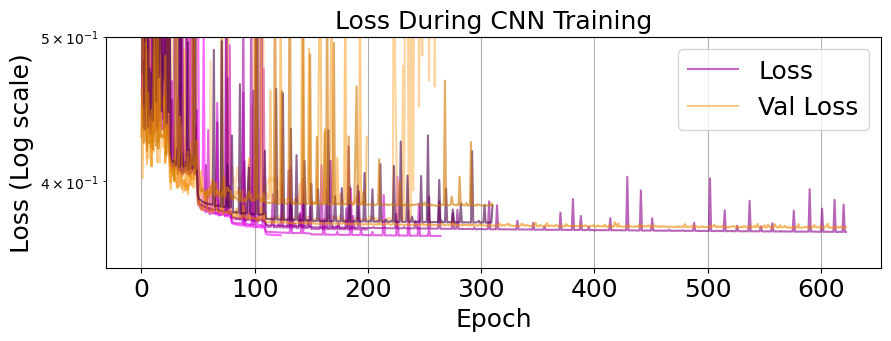

In [29]:
#'newhparam_midstreak',
#"newrange_50_mindelta_p50"
#,  "newrange_25", "newrange_10",
fig, ax = plt.subplots(figsize=(10,3))
keys = ["offset_sat_newhparam_b50_allstamps_satdumbsplit_folds"]#,"offset_nosat_newhparam_b50_allstamps"]#"newrange_25_mindelta_p50","newrange_50", "newrange_50_mindelta", ,"newrange_50_mindelta"]#, "newrange_500",  "offset_sat_small", "less_offset" #"sat_nnbigger",'offset', 
# keys = ["sat_finalhparam_div4","offset_sat_morestamps",  'sat_nnbigger', "sat_nnbigger_nopool",]
# keys = ['newhparam_midstreak',"sat_finalhparam_div4"]#,"offset_sat_morestamps"]
numbers = ["0","1","2","3","4"]
colors = ["orange",  "purple", "green","orange","red"]*2
colors2 = ["purple", "lightskyblue", "mediumpurple",  "limegreen", "bisque"]*2
# valcolors = ["#FDB85D","#FDA430","#ED8802","#CF7602","#A25C02"]
# regcolors = ["#FF00FF","#D100D1","#A300A3","#8B008B","#470047"]
# alpha=.95
# for i, key in enumerate(keys):

for j, number in enumerate(numbers):
    loss = np.load("/home/3155/saved_loss/"+key+"_loss_history"+number+".npy")
    val_loss = np.load("/home/3155/saved_loss/"+key+"_val_loss_history"+number+".npy")
    # accuracy = np.load("/home/3155/saved_loss/"+key+"_accuracy_history"+number+".npy")
    # val_accuracy = np.load("/home/3155/saved_loss/"+key+"_val_accuracy_history"+number+".npy")
    # print(number)
    if number=="2":
        plt.plot(loss, label='Loss', alpha=alpha, c=regcolors[j])
        plt.plot(val_loss, label='Val Loss', alpha=alpha, c=valcolors[j])
    else:
        plt.plot(loss, alpha=alpha, c=regcolors[j])
        plt.plot(val_loss,  alpha=alpha, c=valcolors[j])            
# for j, key in enumerate(['newrange']):
#     loss = np.load("/home/3155/saved_loss/"+key+"_loss_history.npy")
#     val_loss = np.load("/home/3155/saved_loss/"+key+"_val_loss_history.npy")
#     accuracy = np.load("/home/3155/saved_loss/"+key+"_accuracy_history.npy")
#     val_accuracy = np.load("/home/3155/saved_loss/"+key+"_val_accuracy_history.npy")
#     plt.plot(loss, label='loss '+key, alpha=.7, c=colors[i + j+1])
#     plt.plot(val_loss, label='val loss '+key, alpha=.7, c=colors2[i + j + 1])
plt.yscale("log")
plt.legend(fontsize=18)
plt.xlabel("Epoch", fontsize=18)
plt.ylabel("Loss (Log scale)", fontsize=18)
plt.title("Loss During CNN Training", fontsize=18)
plt.ylim(3.5e-1, 5e-1)
plt.tick_params(axis="both", labelsize=18)
# plt.xlim(0,45)
plt.grid()
# plt.xlim(50,90)
# plt.ylim(2e-1, 4.5e-1)

# plt.yscale("log")

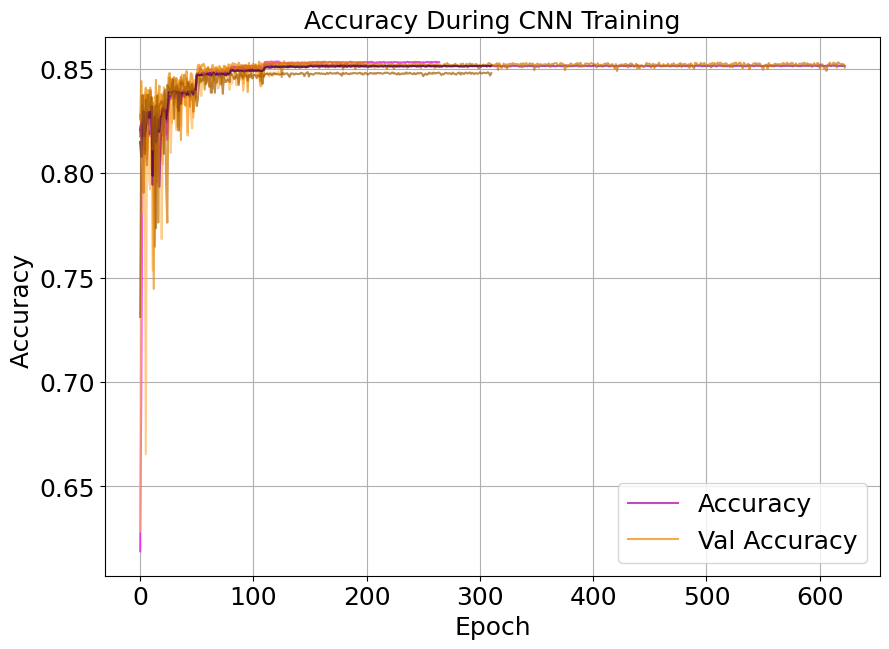

In [19]:
#'newhparam_midstreak',
#"newrange_50_mindelta_p50"
#,  "newrange_25", "newrange_10",
keys = ["offset_sat_newhparam_b50_allstamps_satdumbsplit_folds"]#,"offset_nosat_newhparam_b50_allstamps"]#"newrange_25_mindelta_p50","newrange_50", "newrange_50_mindelta", ,"newrange_50_mindelta"]#, "newrange_500",  "offset_sat_small", "less_offset" #"sat_nnbigger",'offset', 
# keys = ["sat_finalhparam_div4","offset_sat_morestamps",  'sat_nnbigger', "sat_nnbigger_nopool",]
# keys = ['newhparam_midstreak',"sat_finalhparam_div4"]#,"offset_sat_morestamps"]
numbers = ["0","1","2","3","4"]
colors = ["orange",  "purple", "green","orange","red"]*2
colors2 = ["purple", "lightskyblue", "mediumpurple",  "limegreen", "bisque"]*2
for j, number in enumerate(numbers):
    
    # for number in numbers:
        # loss = np.load("/home/3155/saved_loss/"+key+"_loss_history"+number+".npy")
        # val_loss = np.load("/home/3155/saved_loss/"+key+"_val_loss_history"+number+".npy")
        accuracy = np.load("/home/3155/saved_loss/"+key+"_accuracy_history"+number+".npy")
        val_accuracy = np.load("/home/3155/saved_loss/"+key+"_val_accuracy_history"+number+".npy")
        # print(number)
        if number=="2":
            # plt.plot(loss, label='Loss', alpha=.7, c=colors2[i])
            # plt.plot(val_loss, label='Val Loss', alpha=.7, c=colors[i])
            plt.plot(accuracy, label='Accuracy', alpha=.7, c=regcolors[j])
            plt.plot(val_accuracy, label='Val Accuracy', alpha=.7, c=valcolors[j])
        else:
            # plt.plot(loss, alpha=.7, c=colors2[i])
            # plt.plot(val_loss,  alpha=.7, c=colors[i])  
            plt.plot(accuracy,  alpha=.7, c=regcolors[j])
            plt.plot(val_accuracy, alpha=.7, c=valcolors[j])
# for j, key in enumerate(['newrange']):
#     loss = np.load("/home/3155/saved_loss/"+key+"_loss_history.npy")
#     val_loss = np.load("/home/3155/saved_loss/"+key+"_val_loss_history.npy")
#     accuracy = np.load("/home/3155/saved_loss/"+key+"_accuracy_history.npy")
#     val_accuracy = np.load("/home/3155/saved_loss/"+key+"_val_accuracy_history.npy")
#     plt.plot(loss, label='loss '+key, alpha=.7, c=colors[i + j+1])
#     plt.plot(val_loss, label='val loss '+key, alpha=.7, c=colors2[i + j + 1])
# plt.yscale("log")
plt.legend(fontsize=18)
plt.xlabel("Epoch", fontsize=18)
plt.ylabel("Accuracy ", fontsize=18)
plt.title("Accuracy During CNN Training", fontsize=18)
plt.tick_params(axis="both", labelsize=18)
# plt.xlim(0,45)
plt.grid()
# plt.xlim(50,90)
# plt.ylim(2e-1, 4.5e-1)
# plt.ylim(3.5e-1, 4.7e-1)
# plt.yscale("log")

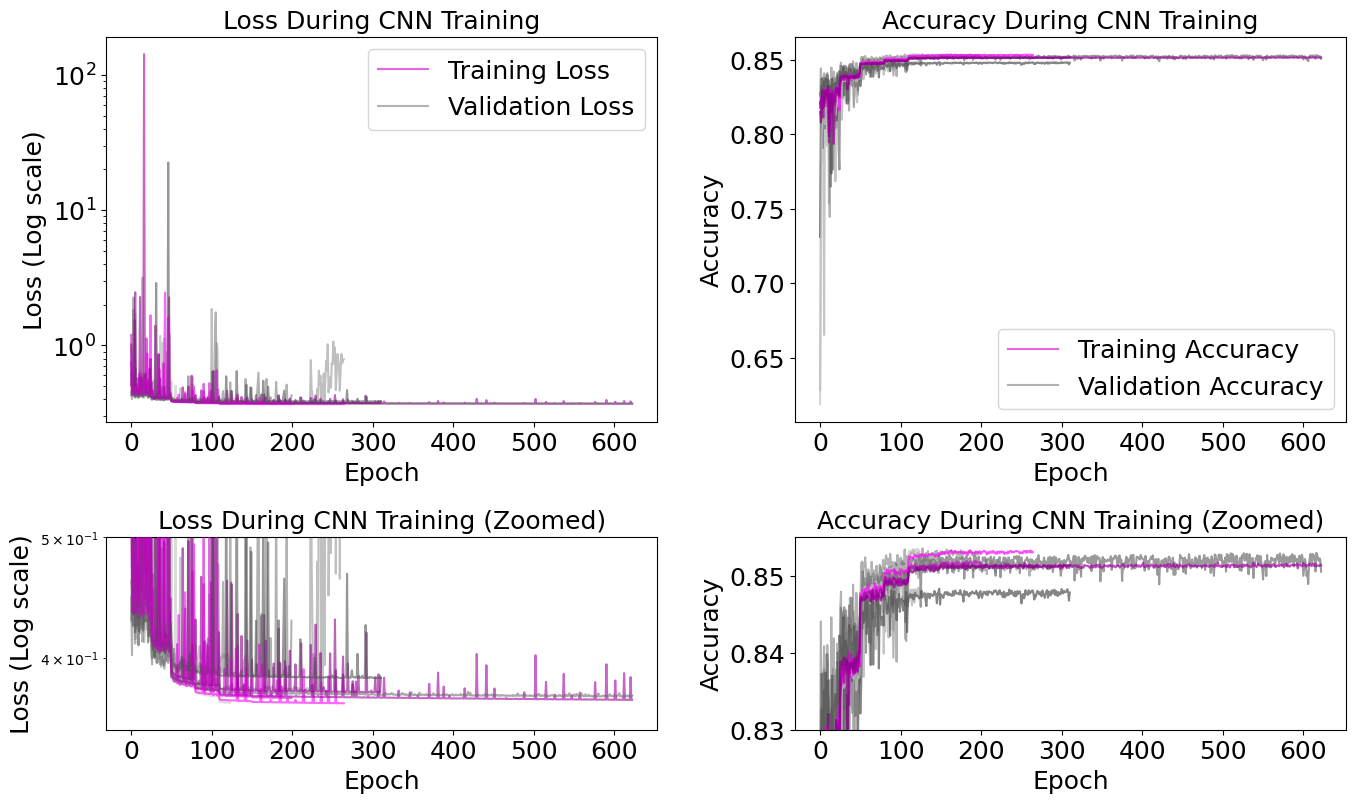

In [55]:


# Configuration
key = "offset_sat_newhparam_b50_allstamps_satdumbsplit_folds"
numbers = ["0", "1", "2", "3", "4"]
# regcolors = ["#FECC8B", "#FDB85D", "#FDA430", "#ED8802", "#CF7602"]
regcolors = ["#C4C4C4","#FF00FF", "#D100D1", "#A300A3", "#8B008B", "#470047"]
valcolors = ["#ADADAD", "#969696", "#808080", "#707070", "#525252"]
alpha = 0.6

# Create figure with 2x2 subplot layout with custom height ratios
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.5], hspace=0.4, wspace=0.25)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[0, 1])
ax4 = fig.add_subplot(gs[1, 1])

# ===== TOP LEFT: Full Loss =====
for j, number in enumerate(numbers):
    loss = np.load(f"/home/3155/saved_loss/{key}_loss_history{number}.npy")
    val_loss = np.load(f"/home/3155/saved_loss/{key}_val_loss_history{number}.npy")
    
    if number == "2":
        ax1.plot(loss, label='Training Loss', alpha=alpha, c=regcolors[j], zorder=10)
        ax1.plot(val_loss, label='Validation Loss', alpha=alpha, c=valcolors[j])
    else:
        ax1.plot(loss, alpha=alpha, c=regcolors[j])
        ax1.plot(val_loss, alpha=alpha, c=valcolors[j])

ax1.set_yscale("log")
ax1.legend(fontsize=18)
ax1.set_xlabel("Epoch", fontsize=18)
ax1.set_ylabel("Loss (Log scale)", fontsize=18)
ax1.set_title("Loss During CNN Training", fontsize=18)
ax1.tick_params(axis="both", labelsize=18)
# ax1.grid(True)

# ===== BOTTOM LEFT: Zoomed Loss =====
for j, number in enumerate(numbers):
    loss = np.load(f"/home/3155/saved_loss/{key}_loss_history{number}.npy")
    val_loss = np.load(f"/home/3155/saved_loss/{key}_val_loss_history{number}.npy")
    
    if number == "2":
        ax2.plot(loss, label='Loss', alpha=alpha, c=regcolors[j], zorder=10)
        ax2.plot(val_loss, label='Val Loss', alpha=alpha, c=valcolors[j])
    else:
        ax2.plot(loss, alpha=alpha, c=regcolors[j])
        ax2.plot(val_loss, alpha=alpha, c=valcolors[j])

ax2.set_yscale("log")
# ax2.legend(fontsize=18)
ax2.set_xlabel("Epoch", fontsize=18)
ax2.set_ylabel("Loss (Log scale)", fontsize=18)
ax2.set_title("Loss During CNN Training (Zoomed)", fontsize=18)
ax2.set_ylim(3.5e-1, 5e-1)
ax2.tick_params(axis="both", labelsize=18)
# ax2.grid(True)

# ===== TOP RIGHT: Full Accuracy =====
for j, number in enumerate(numbers):
    accuracy = np.load(f"/home/3155/saved_loss/{key}_accuracy_history{number}.npy")
    val_accuracy = np.load(f"/home/3155/saved_loss/{key}_val_accuracy_history{number}.npy")
    
    if number == "2":
        ax3.plot(accuracy, label='Training Accuracy', alpha=alpha, c=regcolors[j], zorder=10)
        ax3.plot(val_accuracy, label='Validation Accuracy', alpha=alpha, c=valcolors[j])
    else:
        ax3.plot(accuracy, alpha=0.7, c=regcolors[j], zorder=10)
        ax3.plot(val_accuracy, alpha=0.7, c=valcolors[j])

ax3.legend(fontsize=18)
ax3.set_xlabel("Epoch", fontsize=18)
ax3.set_ylabel("Accuracy", fontsize=18)
ax3.set_title("Accuracy During CNN Training", fontsize=18)
ax3.tick_params(axis="both", labelsize=18)
# ax3.grid(True)

# ===== BOTTOM RIGHT: Zoomed Accuracy =====
for j, number in enumerate(numbers):
    accuracy = np.load(f"/home/3155/saved_loss/{key}_accuracy_history{number}.npy")
    val_accuracy = np.load(f"/home/3155/saved_loss/{key}_val_accuracy_history{number}.npy")
    
    if number == "2":
        ax4.plot(accuracy, label='Accuracy', alpha=alpha, c=regcolors[j], zorder=10)
        ax4.plot(val_accuracy, label='Val Accuracy', alpha=alpha, c=valcolors[j])
    else:
        ax4.plot(accuracy, alpha=0.7, c=regcolors[j], zorder=10)
        ax4.plot(val_accuracy, alpha=0.7, c=valcolors[j])

# ax4.legend(fontsize=18)
ax4.set_xlabel("Epoch", fontsize=18)
ax4.set_ylabel("Accuracy", fontsize=18)
ax4.set_title("Accuracy During CNN Training (Zoomed)", fontsize=18)
ax4.tick_params(axis="both", labelsize=18)
# ax4.grid(True)
# Uncomment to set y-axis limits for zoomed accuracy if needed:
ax4.set_ylim(0.83, 0.855)  # Adjust these values as needed

plt.show()

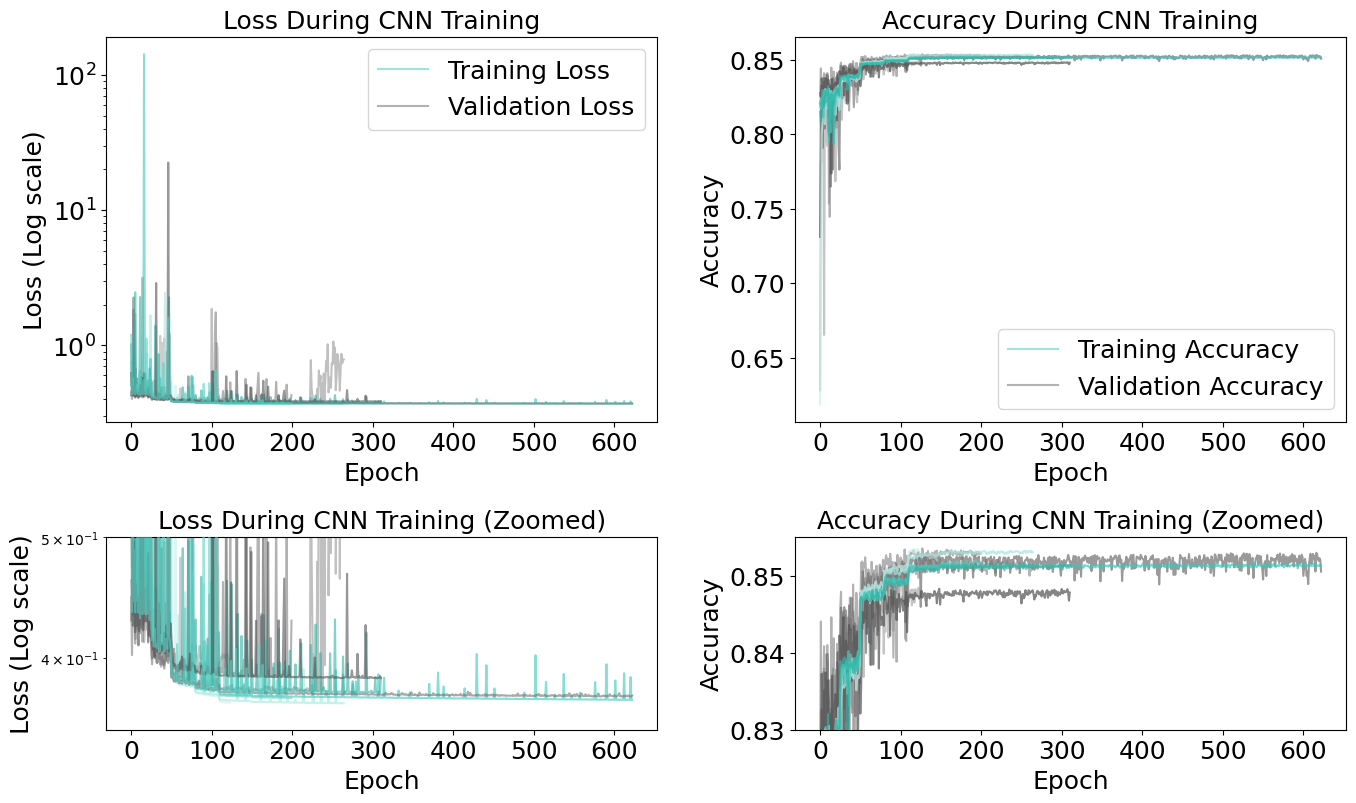

In [12]:


# Configuration
key = "offset_sat_newhparam_b50_allstamps_satdumbsplit_folds"
numbers = ["0", "1", "2", "3", "4"]
# regcolors = ["#FECC8B", "#FDB85D", "#FDA430", "#ED8802", "#CF7602"]
regcolors = ["#C7F0EC","#A3E6DF","#5BD2C6", "#37C8BA", "#31B5A7", "#195C55"]#, "#470047"]
valcolors = ["#ADADAD", "#969696", "#808080", "#707070", "#525252"]
alpha = 0.6

# Create figure with 2x2 subplot layout with custom height ratios
fig = plt.figure(figsize=(16, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 0.5], hspace=0.4, wspace=0.25)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[1, 0])
ax3 = fig.add_subplot(gs[0, 1])
ax4 = fig.add_subplot(gs[1, 1])

# ===== TOP LEFT: Full Loss =====
for j, number in enumerate(numbers):
    loss = np.load(f"/lustre/lrspec/ZTF_data/saved_loss/{key}_loss_history{number}.npy")
    val_loss = np.load(f"/lustre/lrspec/ZTF_data/saved_loss/{key}_val_loss_history{number}.npy")
    
    if number == "2":
        ax1.plot(loss, label='Training Loss', alpha=alpha, c=regcolors[j], zorder=10)
        ax1.plot(val_loss, label='Validation Loss', alpha=alpha, c=valcolors[j])
    else:
        ax1.plot(loss, alpha=alpha, c=regcolors[j])
        ax1.plot(val_loss, alpha=alpha, c=valcolors[j])

ax1.set_yscale("log")
ax1.legend(fontsize=18)
ax1.set_xlabel("Epoch", fontsize=18)
ax1.set_ylabel("Loss (Log scale)", fontsize=18)
ax1.set_title("Loss During CNN Training", fontsize=18)
ax1.tick_params(axis="both", labelsize=18)
# ax1.grid(True)

# ===== BOTTOM LEFT: Zoomed Loss =====
for j, number in enumerate(numbers):
    loss = np.load(f"/lustre/lrspec/ZTF_data/saved_loss/{key}_loss_history{number}.npy")
    val_loss = np.load(f"/lustre/lrspec/ZTF_data/saved_loss/{key}_val_loss_history{number}.npy")
    
    if number == "2":
        ax2.plot(loss, label='Loss', alpha=alpha, c=regcolors[j], zorder=10)
        ax2.plot(val_loss, label='Val Loss', alpha=alpha, c=valcolors[j])
    else:
        ax2.plot(loss, alpha=alpha, c=regcolors[j])
        ax2.plot(val_loss, alpha=alpha, c=valcolors[j])

ax2.set_yscale("log")
# ax2.legend(fontsize=18)
ax2.set_xlabel("Epoch", fontsize=18)
ax2.set_ylabel("Loss (Log scale)", fontsize=18)
ax2.set_title("Loss During CNN Training (Zoomed)", fontsize=18)
ax2.set_ylim(3.5e-1, 5e-1)
ax2.tick_params(axis="both", labelsize=18)
# ax2.grid(True)

# ===== TOP RIGHT: Full Accuracy =====
for j, number in enumerate(numbers):
    accuracy = np.load(f"/lustre/lrspec/ZTF_data/saved_loss/{key}_accuracy_history{number}.npy")
    val_accuracy = np.load(f"/lustre/lrspec/ZTF_data/saved_loss/{key}_val_accuracy_history{number}.npy")
    
    if number == "2":
        ax3.plot(accuracy, label='Training Accuracy', alpha=alpha, c=regcolors[j], zorder=10)
        ax3.plot(val_accuracy, label='Validation Accuracy', alpha=alpha, c=valcolors[j])
    else:
        ax3.plot(accuracy, alpha=0.7, c=regcolors[j], zorder=10)
        ax3.plot(val_accuracy, alpha=0.7, c=valcolors[j])

ax3.legend(fontsize=18)
ax3.set_xlabel("Epoch", fontsize=18)
ax3.set_ylabel("Accuracy", fontsize=18)
ax3.set_title("Accuracy During CNN Training", fontsize=18)
ax3.tick_params(axis="both", labelsize=18)
# ax3.grid(True)

# ===== BOTTOM RIGHT: Zoomed Accuracy =====
for j, number in enumerate(numbers):
    accuracy = np.load(f"/lustre/lrspec/ZTF_data/saved_loss/{key}_accuracy_history{number}.npy")
    val_accuracy = np.load(f"/lustre/lrspec/ZTF_data/saved_loss/{key}_val_accuracy_history{number}.npy")
    
    if number == "2":
        ax4.plot(accuracy, label='Accuracy', alpha=alpha, c=regcolors[j], zorder=10)
        ax4.plot(val_accuracy, label='Val Accuracy', alpha=alpha, c=valcolors[j])
    else:
        ax4.plot(accuracy, alpha=0.7, c=regcolors[j], zorder=10)
        ax4.plot(val_accuracy, alpha=0.7, c=valcolors[j])

# ax4.legend(fontsize=18)
ax4.set_xlabel("Epoch", fontsize=18)
ax4.set_ylabel("Accuracy", fontsize=18)
ax4.set_title("Accuracy During CNN Training (Zoomed)", fontsize=18)
ax4.tick_params(axis="both", labelsize=18)
# ax4.grid(True)
# Uncomment to set y-axis limits for zoomed accuracy if needed:
ax4.set_ylim(0.83, 0.855)  # Adjust these values as needed

plt.show()

In [13]:
for j, number in enumerate(numbers):
    val_loss = np.load(f"/lustre/lrspec/ZTF_data/saved_loss/{key}_val_loss_history{number}.npy")

    best_epoch = np.argmin(val_loss)
    print(f"The best epoch was: {best_epoch + 1}")

The best epoch was: 74
The best epoch was: 215
The best epoch was: 150
The best epoch was: 621
The best epoch was: 263


In [44]:
from sklearn.metrics import f1_score

In [45]:
np.arange(0,5)

array([0, 1, 2, 3])

In [46]:
targ_te = np.load("/home/3155/saved_loss/targ_te_"+save_name+".npy")
label_pred_tes = []
for fold in np.arange(0,5):
    label_pred_tes.append(np.load("/home/3155/saved_loss/label_pred_te_"+save_name+"_fold_"+str(fold)+".npy"))
label_pred_te = np.average(np.array(label_pred_tes),axis=0)

In [50]:
np.argmax(label_pred_te, axis=1)

array([4, 4, 1, ..., 4, 0, 4])

In [52]:
f1_score(y_true=targ_te, y_pred=np.argmax(label_pred_te, axis=1), average=None)

array([0.9753513 , 0.79473379, 0.78093339, 0.97959184, 0.69637774,
       0.99952889])